## Car Sales Data Analysis

### Dataset Overview 
This data contains information about car sales.

### Import Libraries

In [73]:
import pandas as pd

### Read & Review Data

In [6]:
df =pd.read_csv('Car Sales.csv')
df

,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price
0,Ford,Fiesta,1.0,Petrol,2002,127300.0,3074.0
1,Porsche,718 Cayman,4.0,Petrol,2016,57850.0,49704.0
2,Ford,Mondeo,1.6,Diesel,2014,39190.0,24072.0
3,Toyota,RAV4,1.8,Hybrid,1988,210814.0,1705.0
4,VW,Polo,1.0,Petrol,2006,127869.0,4101.0
...,...,...,...,...,...,...,...
50020,Ford,Focus,2.0,Petrol,2002,39712.0,11587.0
50021,Toyota,Yaris,1.0,Petrol,2003,80459.0,5376.0
50022,VW,Polo,1.0,Petrol,1995,168060.0,1420.0
50023,Ford,Fiesta,1.2,Petrol,1994,102413.0,2386.0


In [7]:
df.head()

,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price
0,Ford,Fiesta,1.0,Petrol,2002,127300.0,3074.0
1,Porsche,718 Cayman,4.0,Petrol,2016,57850.0,49704.0
2,Ford,Mondeo,1.6,Diesel,2014,39190.0,24072.0
3,Toyota,RAV4,1.8,Hybrid,1988,210814.0,1705.0
4,VW,Polo,1.0,Petrol,2006,127869.0,4101.0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50025 entries, 0 to 50024
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Manufacturer         50025 non-null  str    
 1   Model                49945 non-null  str    
 2   Engine size          49925 non-null  float64
 3   Fuel type            49775 non-null  str    
 4   Year of manufacture  50025 non-null  int64  
 5   Mileage              49825 non-null  float64
 6   Price                49875 non-null  float64
dtypes: float64(3), int64(1), str(3)
memory usage: 2.7 MB


### Rename Columns

In [10]:
df.rename(columns={'Manufacturer':'Company','Mileage':'Mile(KM)'},inplace=True)
df.head(2)

,Company,Model,Engine size,Fuel type,Year of manufacture,Mile(KM),Price
0,Ford,Fiesta,1.0,Petrol,2002,127300.0,3074.0
1,Porsche,718 Cayman,4.0,Petrol,2016,57850.0,49704.0


### Remove Unneeded Columns

In [ ]:
df.drop(columns={'Engine size'},inplace=True)

In [16]:
df.head(2)

,Company,Model,Fuel type,Year of manufacture,Mile(KM),Price
0,Ford,Fiesta,Petrol,2002,127300.0,3074.0
1,Porsche,718 Cayman,Petrol,2016,57850.0,49704.0


### Check & Handle Null

In [17]:
df.isnull().sum()

Company                  0
Model                   80
Fuel type              250
Year of manufacture      0
Mile(KM)               200
Price                  150
dtype: int64

#### Fill Null in Categorical Data

In [20]:
df['Model']=df['Model'].fillna(df['Model'].mode()[0])
df['Fuel type']=df['Fuel type'].fillna(df['Fuel type'].mode()[0])

#### Fill Null in Numerical Data

In [21]:
df['Mile(KM)']=df['Mile(KM)'].fillna(df['Mile(KM)'].mean())
df['Price']=df['Price'].fillna(df['Price'].mean())

In [22]:
df.isnull().sum()

Company                0
Model                  0
Fuel type              0
Year of manufacture    0
Mile(KM)               0
Price                  0
dtype: int64

### Check & Remove Duplicates

In [24]:
df.duplicated().sum()

np.int64(36)

In [26]:
df[df.duplicated(keep=False)]

,Company,Model,Fuel type,Year of manufacture,Mile(KM),Price
199,Ford,Mondeo,Diesel,2013,79521.0,17370.0
821,VW,Polo,Petrol,1995,168060.0,1420.0
1414,VW,Golf,Petrol,1989,121692.0,1801.0
2183,Ford,Mondeo,Diesel,1987,224569.0,883.0
4144,VW,Golf,Petrol,2005,120820.0,6083.0
...,...,...,...,...,...,...
50020,Ford,Focus,Petrol,2002,39712.0,11587.0
50021,Toyota,Yaris,Petrol,2003,80459.0,5376.0
50022,VW,Polo,Petrol,1995,168060.0,1420.0
50023,Ford,Fiesta,Petrol,1994,102413.0,2386.0


In [28]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [29]:
df.shape

(49989, 6)

### EDA (Exploratory Data Analysis)

In [31]:
# Number of Companies
df['Company'].value_counts()

Company
Ford       14956
VW         14906
Toyota     12553
BMW         4965
Porsche     2609
Name: count, dtype: int64

In [32]:
#Numer of Fuel Type
df['Fuel type'].value_counts()

Fuel type
Petrol    25596
Diesel    13202
Hybrid    11191
Name: count, dtype: int64

In [38]:
#Most Popular Company
df['Company'][0]

'Ford'

In [39]:
df.head(2)

,Company,Model,Fuel type,Year of manufacture,Mile(KM),Price
0,Ford,Fiesta,Petrol,2002,127300.0,3074.0
1,Porsche,718 Cayman,Petrol,2016,57850.0,49704.0


In [45]:
#Average of Price per Company
df.groupby(['Company'])['Price'].mean().sort_values(ascending=False)

Company
Porsche    29088.215349
BMW        24396.470377
Toyota     14323.195718
Ford       10683.503675
VW         10372.347077
Name: Price, dtype: float64

In [46]:
# Number of Cars for each Fuel Type in each Company
df.groupby(['Company'])['Fuel type'].value_counts().sort_values(ascending=False)

Company  Fuel type
Toyota   Hybrid       9676
VW       Petrol       8535
Ford     Petrol       8156
VW       Diesel       5861
Ford     Diesel       5795
BMW      Petrol       3694
Toyota   Petrol       2877
Porsche  Petrol       2334
BMW      Diesel       1271
Ford     Hybrid       1005
VW       Hybrid        510
Porsche  Diesel        275
Name: count, dtype: int64

In [47]:
#Number of models in each Company
df.groupby(['Company'])['Model'].value_counts().sort_values(ascending=False)

Company  Model     
Ford     Mondeo        5069
VW       Golf          5036
         Polo          4981
Ford     Focus         4968
         Fiesta        4919
VW       Passat        4862
Toyota   RAV4          4281
         Prius         4168
         Yaris         4083
BMW      Z4            1682
         M5            1643
         X3            1630
Porsche  Cayenne        870
         911            870
         718 Cayman     867
VW       Mondeo          27
Toyota   Mondeo          21
BMW      Mondeo          10
Porsche  Mondeo           2
Name: count, dtype: int64

In [49]:
#Low Price Cars (Price < 5000) par Company
low_price=df[df['Price']<5000]
low_price.count()
low_price.groupby(['Company'])['Price'].count().sort_values(ascending=False)

Company
VW         6323
Ford       6314
Toyota     4331
BMW        1177
Porsche     451
Name: Price, dtype: int64

In [53]:
#Correlation between Mile(KM) and Price as percentage
round(df.loc[:,['Mile(KM)','Price']].corr()*100,2)

,Mile(KM),Price
Mile(KM),100.00,-62.96
Price,-62.96,100.00


In [54]:
#Correlation Numerical Columns
round(df.describe().corr()*100,2)

,Year of manufacture,Mile(KM),Price
Year of manufacture,100.00,-20.78,11.48
Mile(KM),-20.78,100.00,91.62
Price,11.48,91.62,100.00


### Visualize Data Insights

#### KPI

In [72]:
print('Total Cars : ',df.shape[0])
print('Total Companies : ',df['Company'].nunique())
print('Average of Price : ',df['Price'].mean())
print('Maximum Price : ',df['Price'].max())
print('minimum Price : ',df['Price'].min())
print('average of Miles(KM) : ',df['Mile(KM)'].mean())
print('Oldest Car : ',df['Year of manufacture'].min())
print('Newest Car : ',df['Year of manufacture'].max())

Total Cars :  49989
Total Companies :  5
Average of Price :  13827.269831543392
Maximum Price :  168081.0
minimum Price :  76.0
average of Miles(KM) :  112525.89494767626
Oldest Car :  1984
Newest Car :  2022


<Axes: >

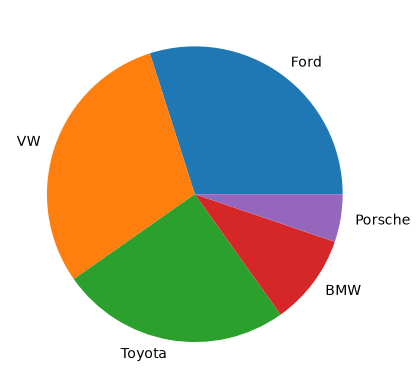

In [66]:
#Total of Companies
df['Company'].value_counts().plot(kind='pie')

<Axes: ylabel='Frequency'>

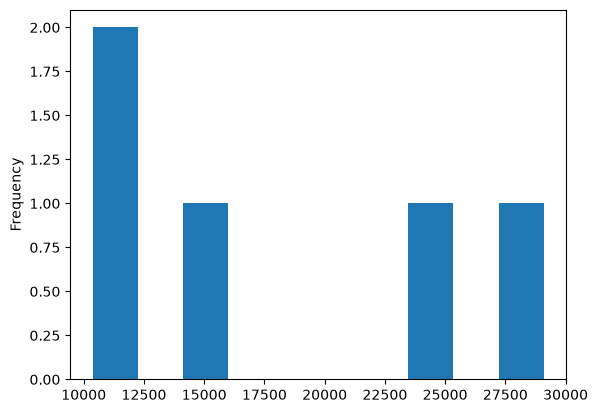

In [55]:
#Average of Price per Company
df.groupby(['Company'])['Price'].mean().sort_values(ascending=False).plot(kind='hist')

<Axes: xlabel='Company,Fuel type'>

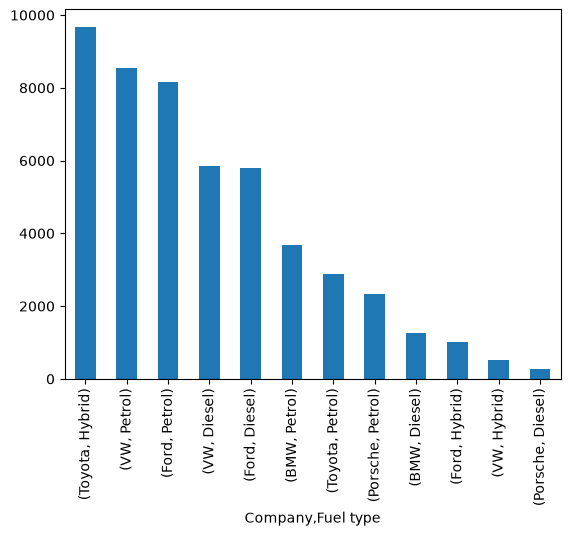

In [56]:
# Number of Cars for each Fuel Type in each Company
df.groupby(['Company'])['Fuel type'].value_counts().sort_values(ascending=False).plot(kind='bar')

<Axes: ylabel='Company,Model'>

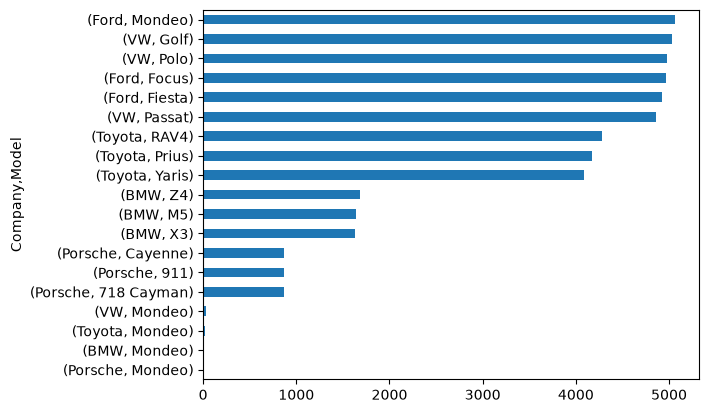

In [60]:
#Number of models in each Company
df.groupby(['Company'])['Model'].value_counts().sort_values().plot(kind='barh')

<Axes: xlabel='Company'>

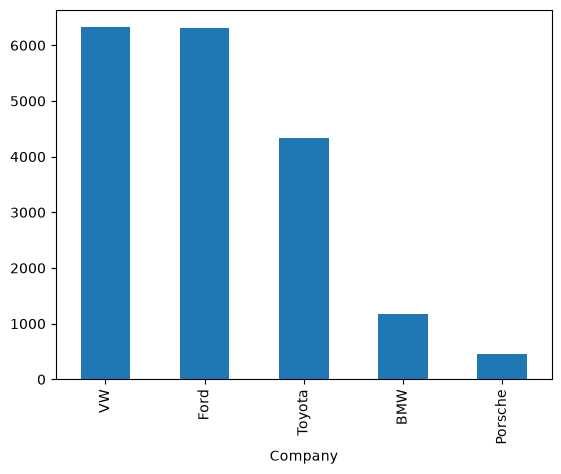

In [64]:
#Low Price Cars (Price < 5000) par Company
low_price.groupby(['Company'])['Price'].count().sort_values(ascending=False).plot(kind='bar')

<Axes: xlabel='Mile(KM)', ylabel='Price'>

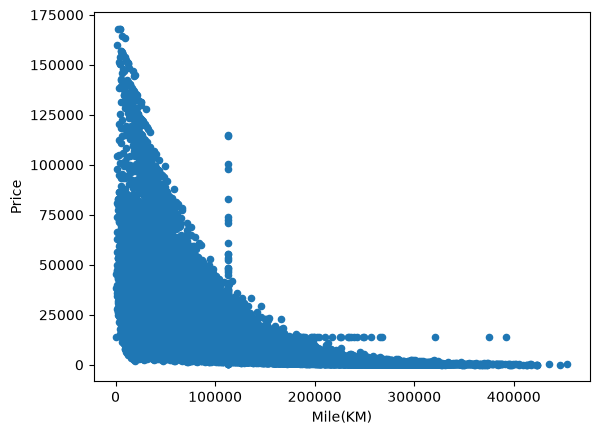

In [65]:
#Correlation between Mile(KM) and Price as percentage
df.plot(kind='scatter',x='Mile(KM)',y='Price')